In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full.csv


In [3]:
filename = next(iter(uploaded))

df = pd.read_csv(filename, sep=None, engine='python')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
print("Number of rows and columns:")
print(df.shape)

Number of rows and columns:
(41188, 21)


In [6]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [9]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [10]:
numerical_features = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = df.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


y
no     36548
yes     4640
Name: count, dtype: int64


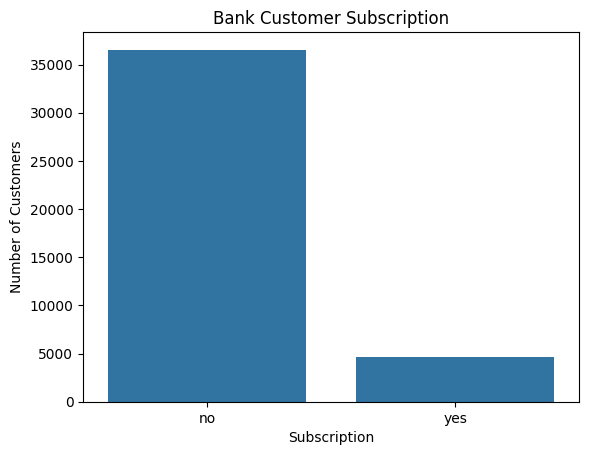

(41188, 21)
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
y
no     36548
yes     4640
Name: count, dtype: int64


In [13]:
print(df['y'].value_counts())
sns.countplot(data=df, x='y')

plt.title("Bank Customer Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()
print(df.shape)
print(df.columns.tolist())
print(df['y'].value_counts())

In [14]:
# Replace empty values with NaN
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

print("Missing values:")
print(df.isnull().sum())

Missing values:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [15]:
df['y'] = df['y'].str.strip().str.lower()

df['y'] = df['y'].map({
    'yes': 1,
    'no': 0
})

df = df.dropna(subset=['y'])

df['y'] = df['y'].astype(int)

print(df['y'].value_counts())

y
0    36548
1     4640
Name: count, dtype: int64


In [16]:
X = df.drop('y', axis=1)

y = df['y']

print("Input variables:")
print(X.head())

print("Output variable:")
print(y.head())

Input variables:
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  duration  campaign  pdays  previous     poutcome  \
0   may         mon       261         1    999         0  nonexistent   
1   may         mon       149         1    999         0  nonexistent   
2   may         mon       226         1    999         0  nonexistent   
3   may         mon       151         1    999         0  nonexistent   
4   may         mon       307         1    999         0  nonexistent   

   emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
0           1.

In [18]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [19]:
for col in numerical_features:

    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X[
        (X[col] < lower) | (X[col] > upper)
    ]

    print(col, ":", len(outliers), "outliers")

age : 469 outliers
duration : 2963 outliers
campaign : 2406 outliers
pdays : 1515 outliers
previous : 5625 outliers
emp.var.rate : 0 outliers
cons.price.idx : 0 outliers
cons.conf.idx : 447 outliers
euribor3m : 0 outliers
nr.employed : 0 outliers


In [20]:
# Numerical preprocessing

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine both preprocessing methods

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Encoding and scaling prepared successfully!")

Encoding and scaling prepared successfully!


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Data splitting completed successfully!")

Training data: (32950, 20)
Testing data: (8238, 20)
Data splitting completed successfully!


In [22]:
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training records: 32950
Testing records: 8238

Training target distribution:
y
0    29238
1     3712
Name: count, dtype: int64

Testing target distribution:
y
0    7310
1     928
Name: count, dtype: int64


In [23]:
# Create Logistic Regression model

log_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train the model
log_model.fit(X_train, y_train)

# Make predictions
y_pred_log = log_model.predict(X_test)

print("Logistic Regression completed successfully!")

Logistic Regression completed successfully!


In [24]:
accuracy = accuracy_score(y_test, y_pred_log)

precision = precision_score(y_test, y_pred_log)

recall = recall_score(y_test, y_pred_log)

f1 = f1_score(y_test, y_pred_log)

print("Logistic Regression Results")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Logistic Regression Results
Accuracy: 0.8651371692158291
Precision: 0.4512
Recall: 0.9116379310344828
F1 Score: 0.6036389582590082


In [26]:
knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Train model
knn_model.fit(X_train, y_train)

# Predictions
y_pred_knn = knn_model.predict(X_test)

print("KNN completed successfully!")
print("KNN Results")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))

print("Precision:", precision_score(y_test, y_pred_knn))

print("Recall:", recall_score(y_test, y_pred_knn))

print("F1 Score:", f1_score(y_test, y_pred_knn))

KNN completed successfully!
KNN Results
Accuracy: 0.907623209516873
Precision: 0.6259426847662142
Recall: 0.44719827586206895
F1 Score: 0.5216844751728472


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
print("Preprocessor:", 'preprocessor' in globals())
print("X_train:", 'X_train' in globals())
print("X_test:", 'X_test' in globals())
print("y_train:", 'y_train' in globals())
print("y_test:", 'y_test' in globals())

Preprocessor: False
X_train: False
X_test: False
y_train: False
y_test: False


In [11]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
from google.colab import files

uploaded = files.upload()

Saving bank-additional-full.csv to bank-additional-full (1).csv


In [13]:
filename = next(iter(uploaded))

df = pd.read_csv(filename, sep=None, engine='python')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [14]:
df.columns = df.columns.str.strip()

df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

df['y'] = df['y'].str.strip().str.lower()

df['y'] = df['y'].map({
    'yes': 1,
    'no': 0
})

df = df.dropna(subset=['y'])

df['y'] = df['y'].astype(int)

X = df.drop('y', axis=1)
y = df['y']

print("Target variable prepared successfully!")

Target variable prepared successfully!


In [15]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [16]:
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing prepared successfully!")

Preprocessing prepared successfully!


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

Training and testing split completed!


In [18]:
print("Preprocessor:", 'preprocessor' in globals())
print("X_train:", 'X_train' in globals())
print("X_test:", 'X_test' in globals())
print("y_train:", 'y_train' in globals())
print("y_test:", 'y_test' in globals())

Preprocessor: True
X_train: True
X_test: True
y_train: True
y_test: True


In [19]:
svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        class_weight='balanced'
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test)

print("SVM completed successfully!")

SVM completed successfully!


In [22]:
print("SVM Results")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm))
print("Recall:", recall_score(y_test, y_pred_svm))
print("F1 Score:", f1_score(y_test, y_pred_svm))

SVM Results
Accuracy: 0.8506919155134741
Precision: 0.42634146341463414
Recall: 0.9418103448275862
F1 Score: 0.5869711215580927


In [23]:
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

# Predictions
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree completed successfully!")

Decision Tree completed successfully!


In [24]:
print("Decision Tree Results")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))

Decision Tree Results
Accuracy: 0.8974265598446225
Precision: 0.547105561861521
Recall: 0.5193965517241379
F1 Score: 0.5328911000552792


In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest completed successfully!")

Random Forest completed successfully!


In [26]:
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

Random Forest Results
Accuracy: 0.9164845836368051
Precision: 0.7158273381294964
Recall: 0.42887931034482757
F1 Score: 0.5363881401617251


In [27]:
from sklearn.ensemble import BaggingClassifier

bagging_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', BaggingClassifier(
        estimator=DecisionTreeClassifier(),
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_model.fit(X_train, y_train)

y_pred_bag = bagging_model.predict(X_test)

print("Bagging completed successfully!")

Bagging completed successfully!


In [28]:
print("Bagging Results")

print("Accuracy:", accuracy_score(y_test, y_pred_bag))
print("Precision:", precision_score(y_test, y_pred_bag))
print("Recall:", recall_score(y_test, y_pred_bag))
print("F1 Score:", f1_score(y_test, y_pred_bag))

Bagging Results
Accuracy: 0.9150279193979121
Precision: 0.6488250652741514
Recall: 0.5355603448275862
F1 Score: 0.5867768595041323


In [29]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    ))
])

ada_model.fit(X_train, y_train)

y_pred_ada = ada_model.predict(X_test)

print("AdaBoost completed successfully!")

AdaBoost completed successfully!


In [30]:
print("AdaBoost Results")

print("Accuracy:", accuracy_score(y_test, y_pred_ada))
print("Precision:", precision_score(y_test, y_pred_ada))
print("Recall:", recall_score(y_test, y_pred_ada))
print("F1 Score:", f1_score(y_test, y_pred_ada))

AdaBoost Results
Accuracy: 0.907623209516873
Precision: 0.631083202511774
Recall: 0.4331896551724138
F1 Score: 0.513738019169329


In [31]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting completed successfully!")

Gradient Boosting completed successfully!


In [ ]:
print("Gradient Boosting Results")

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))

In [33]:
variables = [
    'y_pred_log',
    'y_pred_knn',
    'y_pred_svm',
    'y_pred_dt',
    'y_pred_rf',
    'y_pred_bag',
    'y_pred_ada',
    'y_pred_gb'
]

for var in variables:
    print(var, ":", var in globals())

y_pred_log : False
y_pred_knn : False
y_pred_svm : True
y_pred_dt : True
y_pred_rf : True
y_pred_bag : True
y_pred_ada : True
y_pred_gb : True


In [34]:
print("Logistic Regression:", 'y_pred_log' in globals())
print("KNN:", 'y_pred_knn' in globals())
print("SVM:", 'y_pred_svm' in globals())
print("Decision Tree:", 'y_pred_dt' in globals())
print("Random Forest:", 'y_pred_rf' in globals())
print("Bagging:", 'y_pred_bag' in globals())
print("AdaBoost:", 'y_pred_ada' in globals())
print("Gradient Boosting:", 'y_pred_gb' in globals())

Logistic Regression: False
KNN: False
SVM: True
Decision Tree: True
Random Forest: True
Bagging: True
AdaBoost: True
Gradient Boosting: True


In [35]:
log_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

print("Logistic Regression completed successfully!")

Logistic Regression completed successfully!


In [38]:
svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', class_weight='balanced'))
])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM completed successfully!")

SVM completed successfully!


In [39]:
print("AdaBoost:", 'y_pred_ada' in globals())
print("Gradient Boosting:", 'y_pred_gb' in globals())

AdaBoost: True
Gradient Boosting: True


In [40]:
print("MODEL COMPLETION STATUS")
print("------------------------------")

print("1. Logistic Regression:", 'y_pred_log' in globals())
print("2. KNN:", 'y_pred_knn' in globals())
print("3. SVM:", 'y_pred_svm' in globals())
print("4. Decision Tree:", 'y_pred_dt' in globals())
print("5. Random Forest:", 'y_pred_rf' in globals())
print("6. Bagging:", 'y_pred_bag' in globals())
print("7. AdaBoost:", 'y_pred_ada' in globals())
print("8. Gradient Boosting:", 'y_pred_gb' in globals())

MODEL COMPLETION STATUS
------------------------------
1. Logistic Regression: True
2. KNN: True
3. SVM: True
4. Decision Tree: True
5. Random Forest: True
6. Bagging: True
7. AdaBoost: True
8. Gradient Boosting: True


In [41]:
#finding best model
models_predictions = {
    'Logistic Regression': y_pred_log,
    'KNN': y_pred_knn,
    'SVM': y_pred_svm,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'Bagging': y_pred_bag,
    'AdaBoost': y_pred_ada,
    'Gradient Boosting': y_pred_gb
}

results = []

for name, predictions in models_predictions.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1 Score': f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values(by='F1 Score', ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score
7,Gradient Boosting,0.921704,0.695712,0.542026,0.609328
0,Logistic Regression,0.865137,0.451200,0.911638,0.603639
2,SVM,0.850692,0.426341,0.941810,0.586971
5,Bagging,0.915028,0.648825,0.535560,0.586777
4,Random Forest,0.916485,0.715827,0.428879,0.536388
3,Decision Tree,0.897427,0.547106,0.519397,0.532891
1,KNN,0.907623,0.625943,0.447198,0.521684
6,AdaBoost,0.907623,0.631083,0.433190,0.513738


,Feature,Importance
1,num__duration,0.477080
9,num__nr.employed,0.263631
8,num__euribor3m,0.081531
3,num__pdays,0.051031
7,num__cons.conf.idx,0.029769
62,cat__poutcome_success,0.015454
6,num__cons.price.idx,0.013046
53,cat__month_oct,0.012521
50,cat__month_mar,0.009617
0,num__age,0.009127


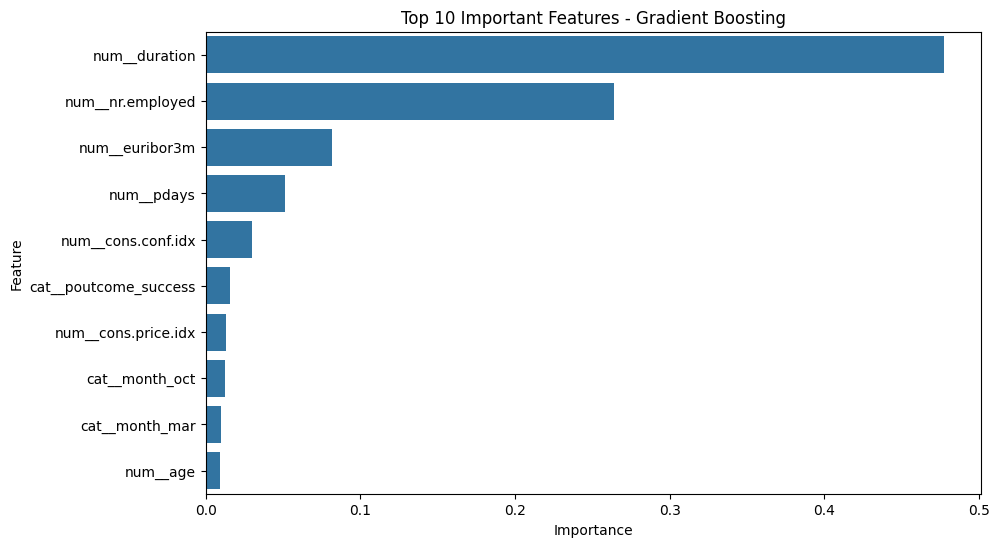

In [42]:
# Get the trained Gradient Boosting classifier
gb_classifier = gb_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = gb_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance
importance = gb_classifier.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance', ascending=False
)

# Display top 10 features
display(feature_importance_df.head(10))

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df.head(10),
    x='Importance',
    y='Feature'
)
plt.title('Top 10 Important Features - Gradient Boosting')
plt.show()

,Feature,Importance
1,num__duration,0.477080
9,num__nr.employed,0.263631
8,num__euribor3m,0.081531
3,num__pdays,0.051031
7,num__cons.conf.idx,0.029769
62,cat__poutcome_success,0.015454
6,num__cons.price.idx,0.013046
53,cat__month_oct,0.012521
50,cat__month_mar,0.009617
0,num__age,0.009127


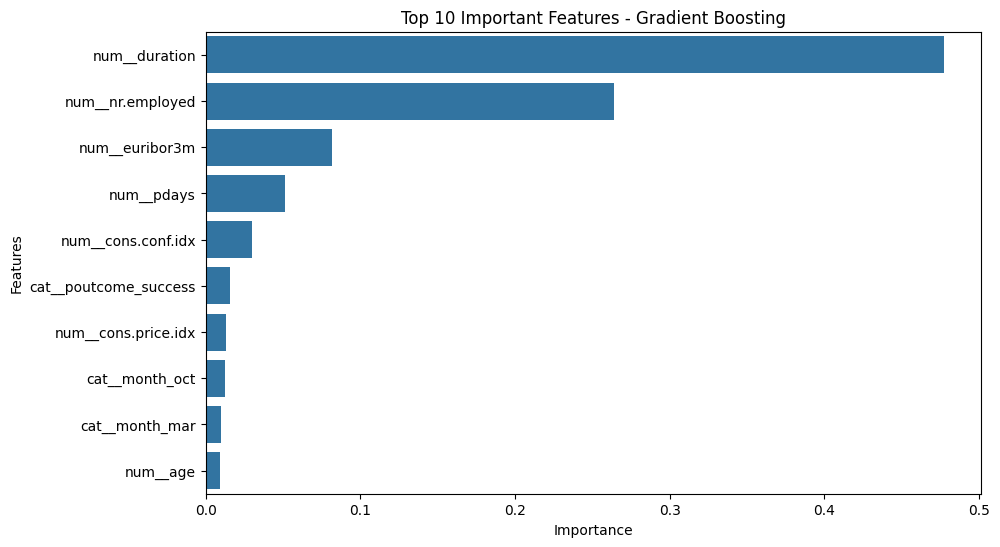

In [43]:
# Get the Gradient Boosting classifier
gb_classifier = gb_model.named_steps['classifier']

# Get feature names
feature_names = gb_model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance
importance = gb_classifier.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

# Sort features by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance', ascending=False
)

# Display top 10 features
display(feature_importance_df.head(10))

# Plot the top 10 features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df.head(10),
    x='Importance',
    y='Feature'
)
plt.title('Top 10 Important Features - Gradient Boosting')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

In [44]:
print("BUSINESS INSIGHTS")
print("----------------------------")

print("1. The Gradient Boosting model achieved the highest F1 Score.")

print("2. The model can help banks identify customers who are")
print("   more likely to subscribe to term deposits.")

print("3. Important features identified through feature importance")
print("   analysis can help banks understand customer behaviour.")

print("4. Banks can use these predictions to improve marketing")
print("   campaigns and reduce unnecessary customer contacts.")

print("5. Since recall is not very high, banks should improve")
print("   their approach to identifying potential subscribers.")

BUSINESS INSIGHTS
----------------------------
1. The Gradient Boosting model achieved the highest F1 Score.
2. The model can help banks identify customers who are
   more likely to subscribe to term deposits.
3. Important features identified through feature importance
   analysis can help banks understand customer behaviour.
4. Banks can use these predictions to improve marketing
   campaigns and reduce unnecessary customer contacts.
5. Since recall is not very high, banks should improve
   their approach to identifying potential subscribers.
